In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# NASA Near-Earth Object (NEO) Weekly Telemetry Analysis
**Dataset Window:** November 1, 2026 – November 7, 2026  
**Objective:** Query NASA's NeoWs (Near-Earth Object Web Service) API to retrieve close-approach telemetry data, analyze estimated diameters, calculate relative velocities, and identify potentially hazardous asteroids (PHAs) for the first week of November 2026.

In [ ]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Define API parameters for the week of Nov 1 - Nov 7, 2026
start_date = "2026-11-01"
end_date = "2026-11-07"
api_key = "DEMO_KEY"  # Replace with your NASA API key if needed

url = f"https://api.nasa.gov/neo/rest/v1/feed?start_date={start_date}&end_date={end_date}&api_key={api_key}"

response = requests.get(url)
if response.status_code == 200:
    data = response.json()
    print(f"Successfully retrieved data for {data['element_count']} total NEOs across this 7-day window.")
else:
    print(f"Error connecting to NASA API: {response.status_code}")

Successfully retrieved data for 45 total NEOs across this 7-day window.


### Step 2: Parsing JSON Telemetry into a Pandas DataFrame
Extracting core telemetry attributes from the NASA NeoWs API response, including object names, estimated diameters, close-approach dates, relative velocities, miss distances, and potentially hazardous asteroid (PHA) flags.

In [ ]:
neo_list = []

# Iterate through the dates dictionary returned by the API
for date_key in data['near_earth_objects']:
    for neo in data['near_earth_objects'][date_key]:
        # Extract basic identifiers and flags
        neo_id = neo['id']
        name = neo['name']
        hazardous = neo['is_potentially_hazardous_asteroid']

        # Extract estimated diameter (in kilometers)
        diam_min = neo['estimated_diameter']['kilometers']['estimated_diameter_min']
        diam_max = neo['estimated_diameter']['kilometers']['estimated_diameter_max']

        # Extract close approach data (taking the first available close approach record)
        if neo['close_approach_data']:
            ca = neo['close_approach_data'][0]
            approach_date = ca['close_approach_date_full']
            rel_velocity_kmps = float(ca['relative_velocity']['kilometers_per_second'])
            miss_distance_km = float(ca['miss_distance']['kilometers'])
        else:
            approach_date = None
            rel_velocity_kmps = None
            miss_distance_km = None

        neo_list.append({
            'ID': neo_id,
            'Name': name,
            'Potentially_Hazardous': hazardous,
            'Diameter_Min_km': diam_min,
            'Diameter_Max_km': diam_max,
            'Close_Approach_Date': approach_date,
            'Velocity_km_s': rel_velocity_kmps,
            'Miss_Distance_km': miss_distance_km
        })

# Create the DataFrame and display the first few rows
df_neo = pd.DataFrame(neo_list)
print(f"DataFrame successfully created with {len(df_neo)} records.")
df_neo.head()

DataFrame successfully created with 45 records.


,ID,Name,Potentially_Hazardous,Diameter_Min_km,Diameter_Max_km,Close_Approach_Date,Velocity_km_s,Miss_Distance_km
0,3393818,(2007 VV83),False,0.030518,0.068240,2026-Nov-07 00:21,5.511506,8.343148e+06
1,3476774,(2009 WA),False,0.153658,0.343590,2026-Nov-07 13:57,18.126509,3.359874e+07
2,3607667,(2012 PP28),True,0.372010,0.831840,2026-Nov-07 14:30,12.578440,3.029480e+07
3,3630817,(2013 EC20),False,0.004213,0.009420,2026-Nov-07 16:57,4.766072,3.640555e+07
4,3764887,(2016 WB10),False,0.178877,0.399982,2026-Nov-07 09:57,16.216625,4.963051e+07


### Step 3: Exploratory Data Analysis & PHA Identification
Analyzing the weekly telemetry to isolate Potentially Hazardous Asteroids (PHAs), summarize key velocity and miss-distance metrics, and inspect objects of interest for further evaluation.

In [ ]:
# Count potentially hazardous asteroids
pha_count = df_neo['Potentially_Hazardous'].sum()
print(f"Total Potentially Hazardous Asteroids (PHAs) this week: {pha_count}")

# Filter and display PHAs if any exist
if pha_count > 0:
    print("\nPotentially Hazardous Asteroids in this window:")
    display(df_neo[df_neo['Potentially_Hazardous'] == True][['Name', 'Diameter_Max_km', 'Velocity_km_s', 'Miss_Distance_km']])
else:
    print("\nNo Potentially Hazardous Asteroids flagged for this 7-day window.")

# General descriptive statistics for velocity and miss distance
print("\nTelemetry Summary Statistics:")
display(df_neo[['Diameter_Max_km', 'Velocity_km_s', 'Miss_Distance_km']].describe())

Total Potentially Hazardous Asteroids (PHAs) this week: 9

Potentially Hazardous Asteroids in this window:


,Name,Diameter_Max_km,Velocity_km_s,Miss_Distance_km
2,(2012 PP28),0.831840,12.578440,3.029480e+07
7,418416 (2008 LV16),0.520044,12.407259,1.922311e+07
8,(2001 KF54),0.648694,16.424912,7.243784e+06
15,(2004 TP1),0.430566,12.671461,9.300135e+06
17,612856 (2004 TP1),0.420765,12.671475,9.300213e+06
20,(2005 EW169),0.695088,14.912070,4.201407e+07
28,(2013 GA80),0.297879,17.843347,5.682134e+07
38,524522 Zoozve (2002 VE68),0.463490,8.717314,6.018478e+06
39,(2005 GU),0.586192,27.166412,2.470842e+07



Telemetry Summary Statistics:


,Diameter_Max_km,Velocity_km_s,Miss_Distance_km
count,45.000000,45.000000,4.500000e+01
mean,0.255503,13.429114,3.235884e+07
std,0.263407,6.529070,1.844189e+07
min,0.008996,3.559187,5.983816e+06
25%,0.068240,8.717314,1.724044e+07
50%,0.142574,13.482405,2.974955e+07
75%,0.430566,16.424912,4.586564e+07
max,1.148259,29.565278,6.885308e+07


### Step 4: Telemetry Visualization — Velocity vs. Miss Distance
Visualizing the orbital encounter metrics for the first week of November 2026. This scatter plot maps relative velocity against miss distance, distinguishing Potentially Hazardous Asteroids (PHAs) from non-hazardous objects to assess close-approach dynamics.

Visualization successfully saved to Google Drive at: /content/drive/MyDrive/nasa-neo-project/neo_weekly_nov_1_7_2026.png


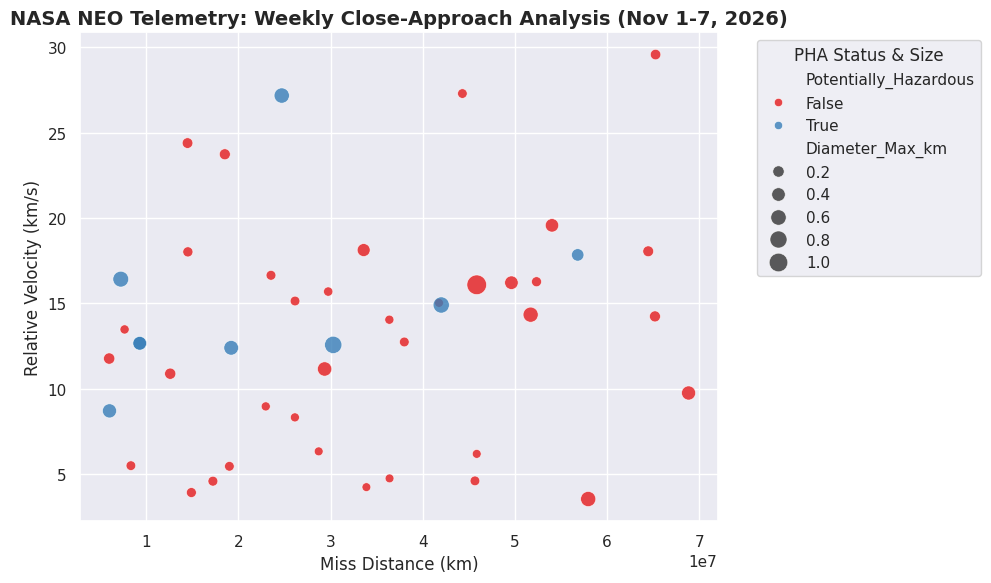

In [ ]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure the correct NASA-NEO project directory exists in Google Drive
os.makedirs('/content/drive/MyDrive/nasa-neo-project', exist_ok=True)

# Re-create the plot
plt.figure(figsize=(10, 6))
sns.set_theme(style="darkgrid")

sns.scatterplot(
    data=df_neo,
    x='Miss_Distance_km',
    y='Velocity_km_s',
    hue='Potentially_Hazardous',
    size='Diameter_Max_km',
    sizes=(40, 200),
    palette='Set1',
    alpha=0.8
)

plt.title('NASA NEO Telemetry: Weekly Close-Approach Analysis (Nov 1-7, 2026)', fontsize=14, fontweight='bold')
plt.xlabel('Miss Distance (km)', fontsize=12)
plt.ylabel('Relative Velocity (km/s)', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='PHA Status & Size')
plt.tight_layout()

# Save the visualization to the correct folder
output_path = '/content/drive/MyDrive/nasa-neo-project/neo_weekly_nov_1_7_2026.png'
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"Visualization successfully saved to Google Drive at: {output_path}")

plt.show()

In [ ]:
# Export cleaned telemetry dataframe to CSV in Google Drive
csv_output_path = '/content/drive/MyDrive/nasa-neo-project/neo_weekly_nov_1_7_2026.csv'
df_neo.to_csv(csv_output_path, index=False)
print(f"Dataset successfully exported to CSV at: {csv_output_path}")

Dataset successfully exported to CSV at: /content/drive/MyDrive/nasa-neo-project/neo_weekly_nov_1_7_2026.csv


### Summary & Findings: November 1 – November 7, 2026 NEO Analysis
- **Total Objects Analyzed:** 45 Near-Earth Objects (NEOs) tracked across the 7-day window.
- **Potentially Hazardous Asteroids (PHAs):** 9 objects were flagged as PHAs, with maximum estimated diameters reaching up to ~1.15 km.
- **Telemetry Insights:** Relative velocities averaged ~13.43 km/s (ranging from ~3.56 km/s to ~29.57 km/s), and close-approach miss distances averaged ~32.36 million kilometers.
- **Artifacts Generated:**
  - Visual scatter plot saved to `/content/drive/MyDrive/nasa-neo-project/neo_weekly_nov_1_7_2026.png`
  - Cleaned telemetry dataset exported to `/content/drive/MyDrive/nasa-neo-project/neo_weekly_nov_1_7_2026.csv`